# Partie B — Exploration de 29 algorithmes de Machine Learning

**Variante distincte de la Partie A**, suivant les mêmes 29 rubriques et le même enchaînement de consignes. Les expériences utilisent d'autres jeux de données et des choix de paramètres différents.

- **Régression :** Diabetes, données réelles de scikit-learn (442 patients, 10 caractéristiques).
- **Classification :** Breast Cancer Wisconsin (569 observations, 30 caractéristiques) — exercice pédagogique, non diagnostic.
- **Clustering :** Wine (178 observations, 13 caractéristiques), avec projection ACP.
- **Réduction de dimension :** Digits (chiffres manuscrits, 64 caractéristiques) — autre jeu que Wine.
- **Renforcement :** Taxi-v3 de Gymnasium et bandit simulé à quatre bras.

**Exécutez les cellules dans l'ordre sur Google Colab.** Les jeux de données intégrés à scikit-learn sont publics et réels ; les bandits et environnements Gymnasium sont des simulations, et non des données observées du monde réel.

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [ ]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

### Présentation

1. Régression linéaire appartient à la famille **régression supervisée**. Son objectif est de prédit une variable quantitative à partir de variables explicatives. les moindres carrés minimisent la somme des carrés des résidus. Le critère essentiel est :

\[
yᵢ = β₀ + Σⱼ βⱼxᵢⱼ + εᵢ
\]

**Définition des symboles :** β₀ et βⱼ sont les paramètres appris ; εᵢ est l’erreur ; les variables x sont les entrées. Il n’y a pas d’hyperparamètre principal dans LinearRegression. Deux avantages : Simple, rapide et interprétable ; fournit une référence solide. Deux limites : Sensible aux valeurs extrêmes et à la non-linéarité ; multicolinéarité pouvant rendre les coefficients instables.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Régression linéaire]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prévision du chiffre d’affaires selon prix et saison .
- **Cas 2 :**  estimation du coût ou délai logistique selon distance et volume.
- **Données et prérequis :** données tabulaires numériques, cible continue, relation approximativement linéaire ; encoder les catégories et examiner les résidus.
- **Cas peu approprié :** classification d’e-mails : la cible n’est pas quantitative.
- **Métriques adaptées :** MAE, RMSE, R² et analyse des résidus.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes (scikit-learn), 442 lignes, 10 variables, cible quantitative ; séparation train/test 75/25, random_state=42.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r² et analyse des résidus permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

### Présentation

2. Ridge appartient à la famille **régression supervisée régularisée L2**. Son objectif est de prédit une cible continue en réduisant l’amplitude des coefficients. ajoute une pénalité quadratique à l’erreur des moindres carrés. Le critère essentiel est :

\[
J(β)=Σᵢ(yᵢ−β₀−xᵢᵀβ)² + αΣⱼβⱼ²
\]

**Définition des symboles :** β désigne les coefficients appris ; α est l’hyperparamètre de régularisation (ici 25). Deux avantages : Réduit la variance et stabilise les coefficients corrélés ; conserve toutes les variables. Deux limites : Réduit aussi les coefficients utiles ; dépend de l’échelle des variables et ne réalise pas une sélection stricte.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Ridge]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prévision du risque de coûts .
- **Cas 2 :**  estimation de ventes avec variables marketing corrélées.
- **Données et prérequis :** variables numériques, cible continue ; standardiser les variables avant pénalisation.
- **Cas peu approprié :** modèle non linéaire avec forte rupture de régime et sans transformation adaptée.
- **Métriques adaptées :** MAE, RMSE, R² ; comparer plusieurs α sur validation.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 observations et 10 variables. Pipeline StandardScaler + Ridge(alpha=25), entraînement sur 75 %.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r² ; comparer plusieurs α sur validation permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

### Présentation

3. Lasso appartient à la famille **régression supervisée régularisée L1**. Son objectif est de prédit une valeur continue et peut sélectionner automatiquement des variables. la pénalité L1 pousse certains coefficients exactement à zéro. Le critère essentiel est :

\[
J(β)=Σᵢ(yᵢ−β₀−xᵢᵀβ)² + αΣⱼ|βⱼ|
\]

**Définition des symboles :** β sont les coefficients appris ; α est l’hyperparamètre (ici 3). Deux avantages : Produit un modèle parcimonieux ; facilite l’identification de variables pertinentes. Deux limites : Peut choisir arbitrairement entre variables corrélées ; trop de pénalisation entraîne un sous-ajustement.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Lasso]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Sélection de facteurs expliquant les ventes .
- **Cas 2 :**  prévision de demande en conservant peu d’indicateurs.
- **Données et prérequis :** variables explicatives numériques mises à l’échelle et cible continue.
- **Cas peu approprié :** données où toutes les variables sont indispensables et fortement redondantes.
- **Métriques adaptées :** MAE, RMSE, R², nombre de coefficients non nuls.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 lignes et 10 variables ; StandardScaler puis Lasso(alpha=3), max_iter=15000.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r², nombre de coefficients non nuls permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

### Présentation

4. Régression polynomiale appartient à la famille **régression supervisée non linéaire**. Son objectif est de modélise une relation courbe en créant des puissances et interactions des variables. transforme X en caractéristiques polynomiales puis ajuste une régression régularisée. Le critère essentiel est :

\[
ŷ=β₀+Σⱼβⱼxⱼ+Σⱼₖβⱼₖxⱼxₖ+…
\]

**Définition des symboles :** β sont les coefficients appris ; degré polynomial et α de Ridge sont des hyperparamètres (degré 2 dans l’exemple). Deux avantages : Capture des courbures ; reste compatible avec les modèles linéaires en paramètres. Deux limites : Le nombre de caractéristiques croît vite ; risque de surapprentissage et extrapolation instable.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Régression polynomiale]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Courbe prix-demande .
- **Cas 2 :**  modélisation des coûts de transport selon distance et charge.
- **Données et prérequis :** relations continues et courbées, nombre modéré de variables ; standardiser et valider le degré.
- **Cas peu approprié :** très grande dimension avec peu d’observations.
- **Métriques adaptées :** MAE, RMSE, R² et comparaison des degrés sur validation.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 observations ; expansion de degré 2 puis Ridge. Le nombre de colonnes transformées dépasse celui des 10 variables initiales.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r² et comparaison des degrés sur validation permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

### Présentation

5. Arbre de régression appartient à la famille **arbre de régression supervisé**. Son objectif est de prédit une valeur continue en découpant l’espace des variables en régions. choisit des seuils qui réduisent l’erreur quadratique dans les feuilles. Le critère essentiel est :

\[
min₍feuilles₎ Σᵢ∈feuille (yᵢ−ȳ_feuille)²
\]

**Définition des symboles :** les seuils et valeurs moyennes des feuilles sont appris ; max_depth=3 et min_samples_leaf=8 sont des hyperparamètres. Deux avantages : Interprétable et capable de relations non linéaires ; peu sensible à la mise à l’échelle. Deux limites : Instable aux variations des données ; peut surapprendre sans élagage.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Arbre de régression]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prévision de demande par segments .
- **Cas 2 :**  estimation de défauts de livraison ou coûts.
- **Données et prérequis :** variables tabulaires et cible continue ; traiter les valeurs manquantes selon l’implémentation.
- **Cas peu approprié :** extrapolation de tendance au-delà des valeurs observées.
- **Métriques adaptées :** MAE, RMSE, R² et profondeur de l’arbre.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 lignes ; arbre limité à profondeur 3 et 8 observations minimum par feuille.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r² et profondeur de l’arbre permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

### Présentation

6. Forêt aléatoire — régression appartient à la famille **ensemble supervisé de régression**. Son objectif est de combine de nombreux arbres entraînés sur des échantillons bootstrap. chaque arbre voit un échantillon tiré avec remise et la prédiction est la moyenne des arbres. Le critère essentiel est :

\[
ŷ(x)=1/B Σ_b T_b(x)
\]

**Définition des symboles :** T_b est l’arbre b appris ; B=120, min_samples_leaf=4 et random_state sont des réglages. Deux avantages : Réduit la variance d’un arbre ; capture interactions et non-linéarités. Deux limites : Moins interprétable et plus coûteux qu’un arbre ; extrapole mal hors du domaine appris.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Forêt aléatoire — régression]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prévision de ventes multi-facteurs .
- **Cas 2 :**  estimation du risque de retard logistique.
- **Données et prérequis :** données tabulaires, assez d’observations, cible continue ; pas de standardisation obligatoire.
- **Cas peu approprié :** série temporelle exigeant une extrapolation de tendance sans variables temporelles adaptées.
- **Métriques adaptées :** MAE, RMSE, R², temps d’entraînement et importance des variables.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 observations ; 120 arbres, feuille minimale 4 ; résultat à lire dans la sortie exécutée.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r², temps d’entraînement et importance des variables permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

### Présentation

7. Gradient Boosting — régression appartient à la famille **ensemble supervisé additif**. Son objectif est de améliore progressivement une prédiction en ajoutant des arbres correcteurs. chaque nouvel arbre approxime les résidus ou le gradient de la fonction de perte. Le critère essentiel est :

\[
Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x)
\]

**Définition des symboles :** Fₘ est le modèle après m étapes ; hₘ l’arbre ajouté ; η, nombre d’itérations et nombre de feuilles sont des hyperparamètres. Deux avantages : Très performant sur données tabulaires ; modélise des relations complexes. Deux limites : Sensible aux hyperparamètres et au bruit ; entraînement séquentiel moins parallélisable.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Gradient Boosting — régression]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prévision de volume de ventes .
- **Cas 2 :**  estimation de délais de livraison.
- **Données et prérequis :** tableau structuré, cible continue ; validation et réglage du nombre d’itérations.
- **Cas peu approprié :** petit jeu de données très bruité ou besoin d’extrapolation lointaine.
- **Métriques adaptées :** MAE, RMSE, R² et temps de calcul.

### Analyse de l'expérience Python

**Entrées et taille :** Diabetes, 442 lignes ; HistGradientBoostingRegressor, max_iter=110 et max_leaf_nodes=12.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Mae, rmse, r² et temps de calcul permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

8. Régression logistique appartient à la famille **classification supervisée probabiliste**. Son objectif est de estime la probabilité qu’une observation appartienne à une classe. combine les variables dans un score linéaire puis applique la fonction sigmoïde. Le critère essentiel est :

\[
P(y=1|x)=1/(1+e⁻ᶻ), z=β₀+xᵀβ
\]

**Définition des symboles :** β sont les coefficients appris ; C inverse la force de régularisation (0,2 dans le pipeline). Deux avantages : Probabilités interprétables ; rapide et bonne référence. Deux limites : Frontière linéaire sauf transformations ; sensible aux variables redondantes et aux relations complexes.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Régression logistique]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Probabilité de défaut de crédit .
- **Cas 2 :**  probabilité de conversion marketing.
- **Données et prérequis :** variables tabulaires, cible catégorielle ; standardiser les variables et contrôler le déséquilibre.
- **Cas peu approprié :** classes séparées par une frontière très complexe sans ingénierie de variables.
- **Métriques adaptées :** précision, rappel, F1, ROC-AUC ou PR-AUC, calibration.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer Wisconsin, 569 observations et 30 variables ; séparation stratifiée 75/25.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Précision, rappel, f1, roc-auc ou pr-auc, calibration permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

### Présentation

9. KNN appartient à la famille **classification supervisée par voisinage**. Son objectif est de attribue la classe majoritaire parmi les k observations les plus proches. calcule une distance, sélectionne les voisins puis vote, éventuellement pondéré. Le critère essentiel est :

\[
ŷ=mode{yᵢ : i∈Nₖ(x)}
\]

**Définition des symboles :** les exemples d’entraînement sont mémorisés ; k=9 et la métrique/pondération sont des hyperparamètres. Deux avantages : Simple et non paramétrique ; frontières de décision flexibles. Deux limites : Prédiction coûteuse sur gros jeux ; sensible à l’échelle et à la dimension.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : KNN]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Segmentation de clients par comportements .
- **Cas 2 :**  tri de dossiers médicaux similaires.
- **Données et prérequis :** variables comparables et standardisées, distance pertinente, données étiquetées.
- **Cas peu approprié :** très grande dimension ou données massives avec latence stricte.
- **Métriques adaptées :** F1, précision, rappel, accuracy et matrice de confusion.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 lignes, 30 variables ; StandardScaler et 9 voisins pondérés.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, accuracy et matrice de confusion permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

10. Naive Bayes appartient à la famille **classification supervisée probabiliste**. Son objectif est de applique le théorème de Bayes avec indépendance conditionnelle des variables. estime les distributions de chaque variable par classe puis calcule les probabilités a posteriori. Le critère essentiel est :

\[
P(C|x) ∝ P(C)∏ⱼP(xⱼ|C)
\]

**Définition des symboles :** P(C) et les paramètres des distributions sont appris ; var_smoothing=1e-8 est un hyperparamètre. Deux avantages : Très rapide ; fonctionne bien comme référence avec peu de données. Deux limites : Hypothèse d’indépendance souvent irréaliste ; probabilités parfois mal calibrées.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Naive Bayes]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Filtrage de demandes de financement .
- **Cas 2 :**  classification de réclamations clients.
- **Données et prérequis :** variables numériques ici modélisées par des gaussiennes, classes connues.
- **Cas peu approprié :** variables fortement dépendantes avec interactions essentielles.
- **Métriques adaptées :** F1, rappel, précision, ROC-AUC et calibration.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 observations ; GaussianNB avec var_smoothing=1e-8.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, rappel, précision, roc-auc et calibration permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

11. Arbre de décision appartient à la famille **arbre de classification supervisé**. Son objectif est de sépare les observations pour obtenir des feuilles aussi homogènes que possible. choisit à chaque nœud la variable et le seuil maximisant la baisse d’impureté. Le critère essentiel est :

\[
Gini=1−Σₖpₖ²
\]

**Définition des symboles :** pₖ est la proportion de classe k dans le nœud ; profondeur 3 et feuille minimale 5 sont des hyperparamètres. Deux avantages : Règles faciles à expliquer ; gère les non-linéarités. Deux limites : Instable ; peut surapprendre et être biaisé par certaines variables.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Arbre de décision]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Décision d’octroi ou d’orientation de dossiers .
- **Cas 2 :**  qualification de prospects.
- **Données et prérequis :** variables tabulaires étiquetées ; contrôle des classes et des feuilles.
- **Cas peu approprié :** données très bruitées où une frontière stable est nécessaire.
- **Métriques adaptées :** F1, précision, rappel, matrice de confusion.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 observations ; profondeur 3, min_samples_leaf=5.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, matrice de confusion permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

12. Forêt aléatoire — classification appartient à la famille **ensemble d’arbres de classification**. Son objectif est de agrège les votes de plusieurs arbres diversifiés. entraîne des arbres sur des échantillons bootstrap et agrège leurs probabilités ou votes. Le critère essentiel est :

\[
P̂(y=k|x)=1/B Σ_b 1[T_b(x)=k]
\]

**Définition des symboles :** T_b sont les arbres appris ; B=110 et max_depth=6 sont des hyperparamètres. Deux avantages : Plus stable qu’un arbre isolé ; capte interactions et non-linéarités. Deux limites : Moins transparent ; mémoire et calcul plus élevés.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Forêt aléatoire — classification]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Détection de défaut de paiement .
- **Cas 2 :**  classification de clients ou de marchandises.
- **Données et prérequis :** données tabulaires étiquetées, variables numériques/catégorielles encodées.
- **Cas peu approprié :** exigence réglementaire d’une explication simple pour chaque décision.
- **Métriques adaptées :** F1, précision, rappel, ROC-AUC/PR-AUC.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 lignes ; 110 arbres de profondeur maximale 6.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, roc-auc/pr-auc permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

13. SVM appartient à la famille **classification supervisée à marge maximale**. Son objectif est de sépare les classes par un hyperplan avec marge maximale. recherche les vecteurs de support ; un noyau RBF permet une frontière non linéaire. Le critère essentiel est :

\[
min ½||w||² + CΣᵢξᵢ sous contraintes de marge
\]

**Définition des symboles :** w et biais sont appris ; ξᵢ mesure les violations ; C=2 et gamma sont des hyperparamètres. Deux avantages : Efficace en dimension élevée ; noyaux pour frontières non linéaires. Deux limites : Coûteux sur grands jeux ; sensible à l’échelle et au choix de C/noyau.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : SVM]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Classification du risque client .
- **Cas 2 :**  tri de produits ou documents.
- **Données et prérequis :** données étiquetées, standardisation indispensable, taille raisonnable.
- **Cas peu approprié :** millions d’observations sans infrastructure adaptée.
- **Métriques adaptées :** F1, précision, rappel, ROC-AUC et matrice de confusion.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 observations ; SVC RBF, C=2 et gamma='scale'.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, roc-auc et matrice de confusion permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

14. Gradient Boosting — classification appartient à la famille **ensemble additif de classification**. Son objectif est de construit une somme d’arbres qui corrigent les erreurs selon une perte différentiable. ajoute séquentiellement des arbres ajustés au gradient négatif de la perte. Le critère essentiel est :

\[
Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x)
\]

**Définition des symboles :** Fₘ est le score appris ; hₘ l’arbre ; η et max_iter sont des hyperparamètres. Deux avantages : Bonne performance tabulaire ; capture interactions. Deux limites : Réglage délicat ; séquentiel et moins interprétable qu’un modèle linéaire.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Gradient Boosting — classification]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Prédiction de défaut client .
- **Cas 2 :**  classification de commandes à risque.
- **Données et prérequis :** variables structurées et étiquettes fiables ; validation stratifiée.
- **Cas peu approprié :** petit jeu de données très bruité ou besoin d’explications simples.
- **Métriques adaptées :** F1, précision, rappel, ROC-AUC/PR-AUC.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 lignes ; HistGradientBoostingClassifier, 100 itérations et 10 feuilles max.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, roc-auc/pr-auc permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

15. AdaBoost appartient à la famille **ensemble adaptatif de classification**. Son objectif est de combine des apprenants faibles en donnant davantage de poids aux exemples mal classés. entraîne un modèle faible, augmente le poids des erreurs puis agrège les prédictions. Le critère essentiel est :

\[
αₜ=½ ln((1−εₜ)/εₜ)
\]

**Définition des symboles :** εₜ est le taux d’erreur pondéré de l’apprenant t ; αₜ son poids ; n_estimators=90 et learning_rate=0,7 sont des hyperparamètres. Deux avantages : Modèle simple à mettre en ensemble ; peut améliorer des apprenants faibles. Deux limites : Sensible aux valeurs aberrantes et au bruit d’étiquetage ; performance dépend des apprenants faibles.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : AdaBoost]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Détection de transactions suspectes .
- **Cas 2 :**  qualification de prospects.
- **Données et prérequis :** données étiquetées, apprenant faible légèrement meilleur que le hasard.
- **Cas peu approprié :** étiquettes très bruitées ou nombreux outliers.
- **Métriques adaptées :** F1, rappel, précision, ROC-AUC.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 observations ; 90 estimateurs et learning_rate=0,7.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, rappel, précision, roc-auc permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

### Présentation

16. XGBoost appartient à la famille **gradient boosting optimisé**. Son objectif est de implémente un boosting d’arbres avec régularisation et optimisation efficace. ajoute des arbres en minimisant une approximation de la perte et pénalise la complexité. Le critère essentiel est :

\[
Obj=Σᵢl(yᵢ,ŷᵢ)+Σₜ[γTₜ+½λ||wₜ||²]
\]

**Définition des symboles :** l est la perte ; Tₜ le nombre de feuilles ; wₜ leurs poids ; γ, λ, profondeur et learning_rate sont des hyperparamètres. Deux avantages : Très performant sur données tabulaires ; régularisation et gestion des valeurs manquantes selon configuration. Deux limites : Nombreux paramètres ; coût et interprétation plus complexes.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : XGBoost]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Scoring de crédit .
- **Cas 2 :**  prévision de demande et optimisation de stock.
- **Données et prérequis :** données structurées étiquetées ; encodage adapté, validation et contrôle du déséquilibre.
- **Cas peu approprié :** données minuscules ou contrainte de transparence stricte.
- **Métriques adaptées :** F1, précision, rappel, ROC-AUC/PR-AUC, temps de calcul.

### Analyse de l'expérience Python

**Entrées et taille :** Breast Cancer, 569 observations ; XGBClassifier avec 100 arbres, profondeur 2 et learning_rate=0,09. Vérifier que xgboost est installé.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** F1, précision, rappel, roc-auc/pr-auc, temps de calcul permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

### Présentation

17. K-means appartient à la famille **clustering partitionnel non supervisé**. Son objectif est de répartit les observations en k groupes autour de centroïdes. affecte chaque point au centroïde le plus proche puis recalcule les moyennes jusqu’à convergence. Le critère essentiel est :

\[
J=ΣᵢΣₖrᵢₖ||xᵢ−μₖ||²
\]

**Définition des symboles :** rᵢₖ vaut 1 si le point i appartient au groupe k ; μₖ est le centroïde appris ; k=3 et n_init=15 sont des hyperparamètres. Deux avantages : Simple et rapide ; groupes faciles à résumer par centroïdes. Deux limites : Il faut choisir k ; sensible aux échelles, outliers et formes non sphériques.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : K-means]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Segmentation de clients .
- **Cas 2 :**  regroupement de produits par caractéristiques commerciales.
- **Données et prérequis :** variables numériques standardisées, distance euclidienne pertinente.
- **Cas peu approprié :** groupes de formes irrégulières et densités très différentes.
- **Métriques adaptées :** silhouette, inertie, stabilité et interprétation métier.

### Analyse de l'expérience Python

**Entrées et taille :** Wine UCI via scikit-learn, 178 vins et 13 variables ; projection ACP 2D utilisée pour visualiser et clusteriser dans ce notebook.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Silhouette, inertie, stabilité et interprétation métier permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

### Présentation

18. Classification hiérarchique appartient à la famille **clustering hiérarchique non supervisé**. Son objectif est de construit une hiérarchie de groupes fusionnés successivement. fusionne les groupes selon une règle de liaison ; Ward minimise l’augmentation de variance intra-groupe. Le critère essentiel est :

\[
ΔW=|A||B|/(|A|+|B|) ||μA−μB||²
\]

**Définition des symboles :** A et B sont deux groupes ; μA et μB leurs centroïdes ; n_clusters=3 et linkage='ward' sont des réglages. Deux avantages : Dendrogramme interprétable ; pas besoin d’initialiser des centroïdes. Deux limites : Coût mémoire/temps élevé ; les fusions sont irréversibles.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Classification hiérarchique]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Groupement de fournisseurs .
- **Cas 2 :**  segmentation de gammes de produits.
- **Données et prérequis :** données numériques standardisées, distance cohérente ; Ward utilise la distance euclidienne.
- **Cas peu approprié :** très grand volume de données ou groupes très non sphériques.
- **Métriques adaptées :** silhouette, stabilité, dendrogramme et interprétation.

### Analyse de l'expérience Python

**Entrées et taille :** Wine, 178 observations ; projection ACP 2D ; AgglomerativeClustering, 3 groupes, Ward.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Silhouette, stabilité, dendrogramme et interprétation permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

### Présentation

19. DBSCAN appartient à la famille **clustering par densité non supervisé**. Son objectif est de détecte des groupes denses et marque les points isolés comme bruit. explore les voisinages de rayon ε et relie les points suffisamment denses. Le critère essentiel est :

\[
Nε(x)={x′ : d(x,x′)≤ε}
\]

**Définition des symboles :** ε est le rayon et min_samples le seuil de densité ; eps=0,7 et min_samples=6 sont hyperparamètres. Deux avantages : Détecte des formes arbitraires ; identifie le bruit sans fixer le nombre de groupes. Deux limites : Très sensible à eps ; difficulté lorsque les densités varient.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : DBSCAN]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Repérage de zones de concentration de clients .
- **Cas 2 :**  détection de flux commerciaux atypiques.
- **Données et prérequis :** variables numériques mises à l’échelle, métrique et densité adaptées.
- **Cas peu approprié :** groupes de densités très différentes ou données haute dimension non préparées.
- **Métriques adaptées :** silhouette hors bruit, proportion de bruit, stabilité et inspection métier.

### Analyse de l'expérience Python

**Entrées et taille :** Wine, 178 observations projetées en 2D par ACP ; DBSCAN eps=0,7, min_samples=6. Le label -1 signifie bruit.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Silhouette hors bruit, proportion de bruit, stabilité et inspection métier permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

### Présentation

20. Mélanges gaussiens appartient à la famille **clustering probabiliste non supervisé**. Son objectif est de représente les données comme un mélange de distributions gaussiennes. estime les poids, moyennes et covariances par l’algorithme EM. Le critère essentiel est :

\[
p(x)=Σₖπₖ N(x|μₖ,Σₖ)
\]

**Définition des symboles :** πₖ sont les poids, μₖ les moyennes, Σₖ les covariances apprises ; nombre de composantes=3 et type de covariance sont hyperparamètres. Deux avantages : Appartenances probabilistes ; modélise des groupes elliptiques. Deux limites : Hypothèse gaussienne ; risque de maxima locaux et choix du nombre de composantes.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Mélanges gaussiens]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Segmentation probabiliste de clients .
- **Cas 2 :**  regroupement de profils de fournisseurs.
- **Données et prérequis :** variables numériques standardisées, choix du nombre de composantes et contrôle de convergence.
- **Cas peu approprié :** structures non gaussiennes ou groupes très irréguliers.
- **Métriques adaptées :** silhouette des labels, BIC/AIC, stabilité et probabilités d’appartenance.

### Analyse de l'expérience Python

**Entrées et taille :** Wine, 178 observations projetées en 2D ; GaussianMixture, 3 composantes, covariance complète.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Silhouette des labels, bic/aic, stabilité et probabilités d’appartenance permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

### Présentation

21. ACP appartient à la famille **réduction de dimension linéaire non supervisée**. Son objectif est de projette les variables sur des axes orthogonaux maximisant la variance. centre les variables, calcule les composantes principales et projette les observations. Le critère essentiel est :

\[
Z=XW ; WᵀW=I
\]

**Définition des symboles :** W contient les vecteurs propres appris ; n_components=2 est un hyperparamètre. Deux avantages : Rapide et reproductible ; variance expliquée mesurable. Deux limites : Ne capture que les relations linéaires ; axes parfois difficiles à interpréter.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : ACP]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Visualisation des profils clients .
- **Cas 2 :**  compression d’indicateurs financiers.
- **Données et prérequis :** variables numériques, standardisation si échelles différentes.
- **Cas peu approprié :** manifold fortement non linéaire que l’on veut préserver fidèlement.
- **Métriques adaptées :** variance expliquée cumulée, reconstruction et visualisation.

### Analyse de l'expérience Python

**Entrées et taille :** Digits, 1 797 images 8×8 représentées par 64 pixels ; ACP à 2 composantes.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Variance expliquée cumulée, reconstruction et visualisation permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

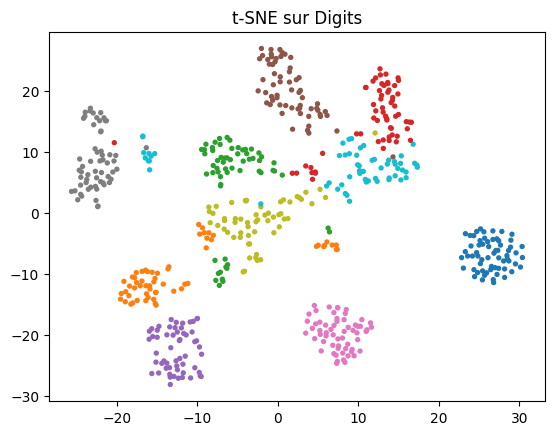

In [24]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

### Présentation

22. t-SNE appartient à la famille **réduction de dimension non linéaire pour visualisation**. Son objectif est de représente en 2D les voisinages locaux d’un espace de grande dimension. convertit les proximités en probabilités puis optimise une divergence entre distributions. Le critère essentiel est :

\[
KL(P||Q)=Σᵢⱼpᵢⱼlog(pᵢⱼ/qᵢⱼ)
\]

**Définition des symboles :** P et Q sont les distributions de voisinage haute et basse dimension ; perplexity=35 et learning rate sont des hyperparamètres. Deux avantages : Visualise des structures locales complexes ; utile pour explorer des classes. Deux limites : Coûteux et sensible aux paramètres ; distances globales entre amas peu interprétables.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : t-SNE]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Exploration de profils de transactions .
- **Cas 2 :**  visualisation de segments de clients.
- **Données et prérequis :** données numériques préparées, échantillon raisonnable et graine fixée.
- **Cas peu approprié :** mesure quantitative des distances globales ou extrapolation à de nouvelles observations.
- **Métriques adaptées :** conservation des voisinages (trustworthiness), stabilité et inspection ; pas de score de classification.

### Analyse de l'expérience Python

**Entrées et taille :** Digits, 1 797 observations et 64 pixels ; t-SNE en 2D, perplexity=35, init='pca'.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Conservation des voisinages (trustworthiness), stabilité et inspection ; pas de score de classification permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


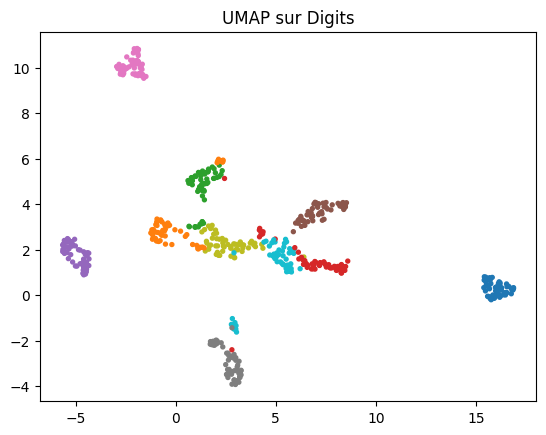

In [25]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

### Présentation

23. UMAP appartient à la famille **réduction de dimension non linéaire**. Son objectif est de construit une représentation basse dimension préservant une structure de voisinage. construit un graphe flou des voisins puis optimise une représentation compacte. Le critère essentiel est :

\[
L=Σᵢⱼwᵢⱼ log(wᵢⱼ/vᵢⱼ)+(1−wᵢⱼ)log((1−wᵢⱼ)/(1−vᵢⱼ))
\]

**Définition des symboles :** wᵢⱼ et vᵢⱼ représentent les affinités dans les espaces initial et projeté ; n_neighbors=20 et min_dist=0,15 sont hyperparamètres. Deux avantages : Préserve souvent bien la structure locale ; rapide sur de nombreux jeux comparé à t-SNE. Deux limites : Résultat dépend des paramètres et de la graine ; distances globales à interpréter avec prudence.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : UMAP]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Exploration de segments de clients .
- **Cas 2 :**  visualisation de familles de produits.
- **Données et prérequis :** données numériques préparées ; bibliothèque umap-learn installée.
- **Cas peu approprié :** analyse où seule une relation linéaire et une variance expliquée sont recherchées.
- **Métriques adaptées :** trustworthiness, conservation des voisins, stabilité et visualisation.

### Analyse de l'expérience Python

**Entrées et taille :** Digits, sous-échantillon de 600 observations, 64 pixels ; UMAP 2D, n_neighbors=20, min_dist=0,15.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Trustworthiness, conservation des voisins, stabilité et visualisation permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [26]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


### Présentation

24. Isolation Forest appartient à la famille **détection non supervisée d’anomalies**. Son objectif est de isole les observations atypiques par des partitions aléatoires. construit des arbres aléatoires ; les anomalies sont isolées en moins de coupures. Le critère essentiel est :

\[
s(x,n)=2^{−E[h(x)]/c(n)}
\]

**Définition des symboles :** h(x) est la profondeur d’isolement ; E sa moyenne ; c(n) normalise selon la taille ; contamination et nombre d’arbres sont hyperparamètres. Deux avantages : Ne nécessite pas d’étiquettes ; adapté aux anomalies multivariées. Deux limites : Score relatif et seuil délicat ; les anomalies collectives peuvent être manquées.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Isolation Forest]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Alertes sur transactions atypiques .
- **Cas 2 :**  détection d’anomalies de stock ou de transport.
- **Données et prérequis :** variables numériques propres, historique représentatif ; définir une politique d’alerte.
- **Cas peu approprié :** détection de fraude confirmée sans aucune donnée ni retour expert.
- **Métriques adaptées :** taux d’alertes, précision/rappel si labels fiables, revue humaine et stabilité.

### Analyse de l'expérience Python

**Entrées et taille :** Wine, 178 observations et caractéristiques projetées ; IsolationForest détecte des points atypiques sans vérité terrain d’anomalie.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Taux d’alertes, précision/rappel si labels fiables, revue humaine et stabilité permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [27]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


### Présentation

25. Bandits manchots appartient à la famille **apprentissage par renforcement de type bandit**. Son objectif est de choisit un bras parmi plusieurs options afin de maximiser le gain cumulé. estime le gain moyen de chaque bras à partir des récompenses observées. Le critère essentiel est :

\[
Qₜ(a)=Σ_{i≤t, Aᵢ=a}Rᵢ / Nₜ(a)
\]

**Définition des symboles :** Qₜ(a) est l’estimation du gain moyen ; Rᵢ les récompenses ; Nₜ(a) le nombre de choix ; les probabilités de récompense sont inconnues. Deux avantages : Méthode simple pour décisions répétées ; adaptation au retour observé. Deux limites : Ignore les transitions d’état ; exploration insuffisante peut bloquer sur un mauvais bras.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Bandits manchots]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Choix d’une campagne publicitaire .
- **Cas 2 :**  sélection d’une offre ou d’un fournisseur à tester.
- **Données et prérequis :** choix répétés et retour mesurable (clic, marge, délai) ; définir coût et récompense.
- **Cas peu approprié :** décision ponctuelle sans retour ou contexte évolutif avec états complexes.
- **Métriques adaptées :** récompense cumulée, regret, taux de sélection et comparaison à une stratégie oracle simulée.

### Analyse de l'expérience Python

**Entrées et taille :** Quatre bras avec probabilités de récompense définies dans le code : environnement simulé, non dataset réel.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Récompense cumulée, regret, taux de sélection et comparaison à une stratégie oracle simulée permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [28]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


### Présentation

26. Epsilon-greedy appartient à la famille **politique de bandit exploration-exploitation**. Son objectif est de équilibre choix aléatoire et choix du bras estimé meilleur. avec probabilité ε explore un bras aléatoire, sinon exploite le meilleur Q estimé. Le critère essentiel est :

\[
Aₜ={random arm avec prob. ε ; argmaxₐQₜ(a) sinon}
\]

**Définition des symboles :** Qₜ(a) est le gain moyen estimé ; ε est l’hyperparamètre d’exploration. Deux avantages : Très facile à implémenter ; garantit une exploration minimale si ε>0. Deux limites : ε fixe peut être trop élevé ou trop faible ; pas de modèle de contexte.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Epsilon-greedy]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Tests a/b de campagnes marketing .
- **Cas 2 :**  allocation d’offres commerciales.
- **Données et prérequis :** récompenses observables après chaque action et bras comparables.
- **Cas peu approprié :** environnement avec changements rapides nécessitant une adaptation contextuelle avancée.
- **Métriques adaptées :** récompense cumulée, regret, taux de clic/conversion et variance entre graines.

### Analyse de l'expérience Python

**Entrées et taille :** Quatre bras simulés avec probabilités fixées ; epsilon-greedy n’est pas évalué sur un CSV réel.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Récompense cumulée, regret, taux de clic/conversion et variance entre graines permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [29]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:511: DeprecationWarning: WARN: The environment Taxi-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


DeprecatedEnv: Environment version v3 for `Taxi` is deprecated. Please use `Taxi-v4` instead.

### Présentation

27. Q-learning appartient à la famille **apprentissage par renforcement hors-politique**. Son objectif est de apprend une valeur d’action optimale à partir des transitions état-action-récompense. met à jour Q avec la meilleure valeur possible du prochain état. Le critère essentiel est :

\[
Q(s,a)←Q(s,a)+α[r+γ maxₐ′Q(s′,a′)−Q(s,a)]
\]

**Définition des symboles :** s,a,s′ sont état, action et état suivant ; r récompense ; α taux d’apprentissage ; γ actualisation ; max sélectionne la meilleure action future. Deux avantages : Apprend une politique gloutonne optimale estimée ; réutilise les transitions. Deux limites : Exploration et convergence sensibles aux paramètres ; table Q peu adaptée aux grands espaces.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : Q-learning]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Optimisation de stock sous états discrets .
- **Cas 2 :**  routage ou planification de décisions séquentielles.
- **Données et prérequis :** environnement interactif avec états/actions discrets et récompenses définies.
- **Cas peu approprié :** données statiques sans interaction ni transition.
- **Métriques adaptées :** récompense cumulée, taux de réussite, longueur d’épisode et variation entre graines.

### Analyse de l'expérience Python

**Entrées et taille :** Taxi-v3 Gymnasium : environnement interactif simulé ; ce ne sont pas des observations d’un CSV réel.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Récompense cumulée, taux de réussite, longueur d’épisode et variation entre graines permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

### Présentation

28. SARSA appartient à la famille **apprentissage par renforcement sur politique**. Son objectif est de apprend la valeur des actions réellement suivies par la politique courante. met à jour Q après avoir choisi l’action suivante avec la politique exploratoire. Le critère essentiel est :

\[
Q(s,a)←Q(s,a)+α[r+γQ(s′,a′)−Q(s,a)]
\]

**Définition des symboles :** s,a,s′,a′ sont état, action, état suivant et action suivante réellement choisie ; α et γ sont des hyperparamètres. Deux avantages : Tient compte de la politique effectivement exécutée ; apprentissage en ligne cohérent. Deux limites : Peut apprendre plus lentement ; dépend de la qualité de l’exploration.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : SARSA]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Pilotage dynamique d’inventaire .
- **Cas 2 :**  séquencement de tâches logistiques.
- **Données et prérequis :** environnement interactif avec récompenses et transitions.
- **Cas peu approprié :** problème purement supervisé avec cible fixe.
- **Métriques adaptées :** récompense cumulée, réussite, durée des épisodes et variance inter-graines.

### Analyse de l'expérience Python

**Entrées et taille :** Taxi-v3 Gymnasium, simulation interactive ; SARSA est on-policy.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Récompense cumulée, réussite, durée des épisodes et variance inter-graines permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

### Présentation

29. DQN — cible conceptuelle appartient à la famille **apprentissage par renforcement profond (cible conceptuelle)**. Son objectif est de utilise un réseau neuronal pour approximer Q(s,a) dans un grand espace d’états. le réseau prédit les valeurs d’action et apprend à partir d’une cible de Bellman ; le notebook illustre seulement cette cible. Le critère essentiel est :

\[
y=r+γ(1−d) maxₐ′Q_target(s′,a′)
\]

**Définition des symboles :** r est la récompense ; γ le facteur d’actualisation ; d indique fin d’épisode ; Q_target est le réseau cible ; le réseau en ligne est ajusté. Mémoire et fréquence de mise à jour sont des hyperparamètres. Deux avantages : Gère des états de grande dimension ; apprend des représentations complexes. Deux limites : Instable et coûteux ; demande beaucoup d’interactions et de réglages.

### Schéma explicatif

```mermaid
flowchart TD
 A[Observations en entrée] --> B[Préparation des variables]
 B --> C[Calcul / apprentissage : DQN — cible conceptuelle]
 C --> D[Modèle, groupes ou politique appris]
 D --> E[Prédiction, projection ou décision]
 E --> F[Évaluation et interprétation]
```

**Lecture :** les observations préparées alimentent le mécanisme propre à l’algorithme ; celui-ci produit une sortie qui doit être évaluée sur des données ou épisodes non utilisés pour régler le modèle. Ce schéma est original et conceptuel.

### Contextes d'utilisation

- **Cas 1 :** Contrôle de systèmes logistiques simulés .
- **Cas 2 :**  allocation séquentielle de ressources.
- **Données et prérequis :** environnement Gymnasium interactif, réseau, replay buffer et calcul adapté.
- **Cas peu approprié :** petit problème tabulaire où Q-learning suffit.
- **Métriques adaptées :** récompense cumulée, taux de réussite, stabilité entre graines et coût de calcul.

### Analyse de l'expérience Python

**Entrées et taille :** La cellule calcule des cibles de Bellman sur des exemples numériques : aucun réseau neuronal n’est entraîné et aucune performance DQN n’est mesurée.
**Paramètres du code :** consulter la cellule Python immédiatement au-dessus ; les paramètres importants sont ceux explicités dans la présentation. La sortie affichée par l'exécution constitue la seule source des valeurs numériques : aucune métrique n'est anticipée ici.

**Interprétation et limites :** Récompense cumulée, taux de réussite, stabilité entre graines et coût de calcul permettent d'évaluer la tâche, mais ne prouvent pas à eux seuls la causalité ni la qualité en production. Pour les méthodes exploratoires ou de renforcement, interpréter les sorties selon leur nature (projection, groupes, anomalies ou récompenses) et non comme une précision de classification.

**Variation d'hyperparamètre à réaliser :** comparer le réglage du code avec une seconde valeur (par exemple α pour Ridge/Lasso, profondeur pour un arbre, k pour KNN/K-means, eps pour DBSCAN, perplexity pour t-SNE, ε pour epsilon-greedy, ou α/γ pour Q-learning/SARSA). Garder `random_state=42`, réutiliser exactement la même séparation ou le même environnement et comparer les métriques pertinentes. Ne pas choisir le réglage sur le test final.


## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [ ]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x=X_reg[:,2].copy();x=(x-x.mean())/x.std();y=y_reg.copy()
poids=0.;biais=y.mean();pas=.015
for iteration in range(3000):
    erreur=poids*x+biais-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Manuel:',round(poids,3),round(biais,3))
from sklearn.linear_model import LinearRegression
modele_ref=LinearRegression().fit(x.reshape(-1,1),y)
print('Scikit-learn:',modele_ref.coef_.round(3),round(modele_ref.intercept_,3))

In [ ]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs=X_clu.copy();k=3;generateur=np.random.default_rng(GRAINE)
centroides=valeurs[generateur.choice(len(valeurs),size=k,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroides[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==j].mean(axis=0) if np.any(groupes==j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux,centroides):break
    centroides=nouveaux
inertie=np.sum((valeurs-centroides[groupes])**2)
from sklearn.cluster import KMeans
reference=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:',round(inertie,2),'Inertie sklearn:',round(reference.inertia_,2))
# Attention : K-means est sensible à l'initialisation ; les deux inerties peuvent différer.

Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.

# Partie B — Traçabilité des données publiques et protocole expérimental (Q5–Q8)

## Q5 — Jeux de données et provenance

Les cellules de préparation chargent quatre jeux de données publics distribués par `scikit-learn` :

| Jeu | Usage dans ce notebook | Dimensions connues du jeu chargé | Cible | Source documentaire |
|---|---|---:|---|---|
| Diabetes | Régression | 442 × 10 | mesure quantitative de progression du diabète | https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset |
| Breast Cancer Wisconsin (Diagnostic) | Classification | 569 × 30 | diagnostic bénin/malin (cible binaire) | https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset |
| Wine recognition | Clustering | 178 × 13 à l'origine ; projection ACP 2D dans ce notebook | trois classes connues, non utilisées pour entraîner le clustering | https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-recognition-dataset |
| Optical recognition of handwritten digits | Réduction de dimension | 1 797 × 64 | chiffres 0 à 9, uniquement pour interpréter les projections | https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset |

**Date de consultation du support : 10 novembre 2026.** Les jeux sont récupérés par les fonctions `load_diabetes`, `load_breast_cancer`, `load_wine` et `load_digits`. Les pages officielles ci-dessus décrivent les données et leur provenance. Les conditions de redistribution doivent être vérifiées sur les pages sources originales avant toute republication ; ne pas supposer une licence unique pour les quatre jeux.

## Q6 — Préparation et prévention des fuites

- Les tableaux fournis par les chargeurs scikit-learn sont numériques et prêts à être utilisés dans les exemples. Vérifier systématiquement `np.isnan(X).sum()`, `pd.DataFrame(X).duplicated().sum()` et `pd.DataFrame(X).describe()` avant une étude finale.
- `StandardScaler` est placé dans un `Pipeline` pour Ridge, Lasso, régression logistique, KNN et SVM : lorsqu'il est ajusté par `fit` sur `Xr_ent` ou `Xc_ent`, ses paramètres proviennent de l'entraînement.
- **Point à corriger pour une évaluation rigoureuse :** `X_clu` est calculé par une ACP ajustée sur tout le jeu Wine avant le clustering. Pour éviter une fuite dans une validation, ajuster le scaler et l'ACP uniquement sur les données d'entraînement, ou présenter cette projection uniquement comme exploration descriptive.
- **Point à corriger pour Digits :** `X_images` est standardisé avant la réduction de dimension sur l'ensemble des observations. Pour une évaluation strictement séparée, ajuster le scaler sur le sous-ensemble d'entraînement uniquement.
- Les séparations régression et classification utilisent `random_state=42`; la classification est stratifiée. Aucun réglage ne doit être choisi sur le jeu de test.

## Q7 — Portée des expériences présentes

Les cellules fournies sont des expériences de démonstration sur des jeux publics réels pour les familles supervisées, le clustering et la réduction de dimension. Elles ne constituent pas encore une comparaison exhaustive avec validation et recherche d'hyperparamètres pour les 29 méthodes.

- Régression : Diabetes, séparation train/test 75/25.
- Classification : Breast Cancer, séparation stratifiée train/test 75/25.
- Clustering : Wine, les caractéristiques sont réduites à deux dimensions avant les méthodes de regroupement. C'est une simplification pédagogique ; une comparaison finale devrait également être faite sur les 13 variables standardisées.
- Réduction de dimension : Digits, 64 pixels par observation.
- Isolation Forest : détection non supervisée sans étiquettes d'anomalies fiables dans l'expérience.
- Bandits : les récompenses proviennent d'un générateur simulé ; ce n'est pas un dataset réel.
- Q-learning et SARSA : Taxi-v3 est un environnement interactif Gymnasium ; les trajectoires sont générées par interaction. Ce n'est pas un CSV de données réelles.
- DQN : la cellule calcule uniquement une cible de Bellman. Aucun réseau n'est entraîné ; l'expérience DQN complète est facultative selon les consignes.

## Q8 — Comparaison, métriques et interprétation

| Famille | Référence à comparer | Méthode avancée | Métriques |
|---|---|---|---|
| Régression | Régression linéaire | Forêt aléatoire ou Gradient Boosting | MAE, RMSE, R² |
| Classification | Régression logistique | SVM, Random Forest, XGBoost ou Gradient Boosting | F1, précision, rappel, ROC-AUC ; PR-AUC si déséquilibre marqué |
| Clustering | K-means | DBSCAN ou mélange gaussien | silhouette, stabilité, proportion de bruit et interprétation métier |
| Réduction de dimension | ACP | t-SNE ou UMAP | variance expliquée pour ACP ; trustworthiness et conservation des voisins pour les méthodes non linéaires |
| Anomalies | règle simple fondée sur l'écart-type (à ajouter) | Isolation Forest | précision/rappel uniquement si des labels fiables existent ; sinon revue des alertes |
| Renforcement | politique aléatoire / epsilon-greedy | Q-learning et SARSA | récompense cumulée, taux de réussite, longueur d'épisode et variation entre graines |

**À ne pas conclure sans exécution :** les métriques exactes, la supériorité d'un modèle, la stabilité entre graines ou le coût mesuré. Exécuter les cellules dans Colab, conserver les sorties, puis compléter la comparaison avec plusieurs graines et un ensemble de validation. Les performances ne doivent pas être inventées.

## Exécution dans Google Colab

1. Téléverser ce fichier `.ipynb` dans Google Colab (`Fichier` → `Importer un notebook`).
2. Exécuter les cellules dans l'ordre, notamment la première cellule d'installation des bibliothèques.
3. Si une erreur apparaît lors de l'import de XGBoost, Gymnasium ou UMAP, relancer la cellule d'installation puis le runtime.
4. Les cellules de renforcement nécessitent un environnement Gymnasium et peuvent prendre plus de temps.
5. Enregistrer une copie du notebook après exécution afin de conserver les sorties réelles.

**Important — format de fichier :** ce projet est un notebook Python. Un fichier SQL ne peut pas remplacer les cellules Python ni exécuter les algorithmes scikit-learn. Le fichier `.ipynb` est le format directement importable dans Colab.
